# L09 · NB 03 — Pretrained sentence embeddings

> *Now we plug in the real thing: a sentence-transformer pretrained on > 1 billion sentence pairs. Same machinery as our toy embedding, but with a corpus and capacity bigger by ~7 orders of magnitude.*

⏱️ **~35 min** in-class code-along (first run adds a one-time ~80 MB model download). The 🟡 Extension section is optional self-study.

### 👟 Step into Sarah's shoes

**Where we left off (NB 02).** Sarah hand-built a tiny embedding and saw meaning start to emerge — but it was weak: *frock ↔ dress* scored only **0.035**, because her toy corpus was just 76 product descriptions. The *idea* works; it just needs vastly more data than she could ever build herself.

**Sarah's realisation:** she doesn't have to. Someone has already trained a model on **a billion+ sentences**. She can borrow it.

> *"Same machinery as my toy embedding — but trained on the whole internet instead of 76 product blurbs. Will it finally know that frock means dress? And will it actually beat my keyword baseline from NB 01?"*

**What Sarah wants to achieve here.** Swap her hand-made vectors for a real pretrained **sentence-transformer**, confirm it understands synonyms, and **grade it on the exact 8-query benchmark she defined in NB 01** — turning "this feels better" into a measured win.

**How she'll do it — step by step:**

1. **Load `all-MiniLM-L6-v2`** — a small, fast, pretrained model. One line of code.
2. **Embed a few sentences** — see any text become a 384-number vector via `.encode()`.
3. **The synonym test** — re-run the pairs her toy model flunked. Watch frock/dress jump from 0.035 → ~0.25. *(Important lesson: read the scores as a* ***ranking signal***, *not a "percent similar".)*
4. **Embed the whole catalogue** — once, then cache it (this is what production does).
5. **Re-run "blue summer dress"** — the query that failed in NB 01.
6. **Grade against ground truth** — beat the 5/8 keyword baseline.
7. **Visualise in 2D** — see far tighter clusters than the toy model's. *That's* what a billion sentences buys.

> The payoff: dresses keyword search couldn't see at all (like the Cassia Maxi Gown) finally show up in the results, and Sarah can prove the upgrade with the same benchmark Marcus saw fail. Next, NB 04 makes it production-ready.

## 1 · Setup + load the model

In [10]:
# --- Colab setup: install sentence-transformers if missing (no-op in the local dsai-m3 env) ---
try:
    import sentence_transformers  # library fetches models from the Hugging Face Hub — the public model-hosting site at huggingface.co. 
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'sentence-transformers'], check=True)

import os
os.environ['HF_HUB_DISABLE_TELEMETRY'] = '1'

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer

# Turn off Hugging Face progress bars. In Jupyter they render as interactive widgets, and
# editors without widget support (e.g. VS Code on WSL) show 'Could not render content for
# application/vnd.jupyter.widget-view+json' instead. Harmless, but confusing — so we silence them.
from transformers.utils import logging as hf_logging
from huggingface_hub.utils import disable_progress_bars
hf_logging.disable_progress_bar()
disable_progress_bars()

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA

# (Removed the old one-CPU-thread cap — it made CPU-only machines much slower.)
np.random.seed(42)

# The star of the show: all-MiniLM-L6-v2, a real sentence-transformer pretrained on 1B+
# sentences (22M params, turns any sentence into a 384-number vector).
MODEL_NAME = 'all-MiniLM-L6-v2'
# Note: exact similarity scores can shift slightly between library/model versions.
# All numbers quoted in the markdown of this lesson are approximate for that reason.

# Download only if needed. SentenceTransformer caches to ~/.cache/huggingface after the first
# pull, so we first try a *local-only* load (no network). If the model is already cached this
# succeeds instantly and we skip the download; if it's missing it raises, and we download.
try:
    model = SentenceTransformer(MODEL_NAME, local_files_only=True)  # offline attempt: cache hit?
    print(f"✅ '{MODEL_NAME}' already cached — skipping download.")
except Exception:
    print(f"⬇️  '{MODEL_NAME}' not found in cache — downloading ~80 MB from Hugging Face (one-time)...")
    model = SentenceTransformer(MODEL_NAME)  # pulls from huggingface.co, then caches for next time
    print("✅ Download complete and cached for future runs.")

n_params = sum(p.numel() for p in model.parameters())
print(f"Model           : {MODEL_NAME}")
print(f"Parameters      : {n_params:,}")
print(f"Embedding dim   : {model.get_embedding_dimension()}")

✅ 'all-MiniLM-L6-v2' already cached — skipping download.
Model           : all-MiniLM-L6-v2
Parameters      : 22,713,216
Embedding dim   : 384


**22 million parameters, 384-dim output.** Tiny by modern standards (BERT-base is 110M; GPT-4 is ~1T) but powerful enough to crush keyword search.

Every sentence we feed in comes out as a **384-dim vector**. Compare that with NB 02: the toy co-occurrence matrix was 552 × 552 (= 304,704 numbers), and each *word* got one 552-number row of it — ~98% zeros, and only for words that appeared in our 76 descriptions.

The pretrained model uses **fewer numbers (384), every one of them carries information (dense), and it describes a whole sentence** — including words our catalogue never contained. Smaller *and* richer: that's what learning from a billion sentences buys over counting words in 76.

## 2 · Embed a few sentences

Now we use the model. The whole interface is one method: `model.encode(list_of_texts)` hands back one vector per text. We feed in **4 sentences** and inspect what comes out.

In [11]:
sentences = [
    "blue summer dress",
    "lightweight floral frock perfect for warm summer days",
    "thermal-lined waterproof snow boots",
    "Chunky cable-knit pullover in cream wool blend",
]

emb = model.encode(sentences)  # the whole magic in one line: hand it text, get back vectors
print(f"Output shape: {emb.shape}")  # confirm each sentence becomes a 384-number row
print(f"Each row is a 384-dim vector.")
print()
# Show first few values of first vector
print(f"First sentence first 8 dims: {emb[0][:8]}")
print(f"L2 norm: {np.linalg.norm(emb[0]):.3f}  (normalised by default)")
# 'L2-normalised' = each vector's length is set to 1, so comparing two vectors
# measures only their direction (the angle between them) — which is where meaning lives.
# Because output is already normalised, cosine similarity simplifies to a plain dot product.

Output shape: (4, 384)
Each row is a 384-dim vector.

First sentence first 8 dims: [-0.09414876  0.03705965  0.06258423  0.04386491  0.03450783  0.01671423
  0.09338306 -0.07202805]
L2 norm: 1.000  (normalised by default)


### How to read the output above

```
Output shape: (4, 384)
```

This is the shape of the result: **4 rows × 384 columns**. One **row per sentence** we passed in, and each row is a list of **384 numbers** — the embedding. (In NB 02 our toy vectors had 552 dimensions, one per vocab word; this real model packs meaning into a fixed 384 *regardless* of vocabulary size.)

```
First sentence first 8 dims: [-0.094  0.037  0.063  0.044  0.035  0.017  0.093 -0.072]
```

These are just the **first 8 of the 384 numbers** for sentence #0 (`"blue summer dress"`). Don't try to interpret any single number — individually they mean nothing to a human. What matters is the *whole* 384-number pattern, and how close it points to another sentence's pattern (that's the synonym test in Step 3). They're a mix of small positive and negative values, which is normal.

```
L2 norm: 1.000  (normalised by default)
```

The **L2 norm** is the geometric *length* of the vector (√ of the sum of its squared values). The model returns it as **exactly 1.0** — every embedding has been scaled to sit on a unit sphere. Why this matters:

> When all vectors have length 1, comparing two of them by **cosine similarity** (the angle between them — the "compass direction" idea from NB 02) becomes the same as a plain **dot product**. That's why later cells can just write `np.dot(a, b)` instead of the full cosine formula — the normalisation already did half the work.

**The takeaway:** any text in → a fixed 384-number, length-1 vector out. That's the entire job of the model. Everything that follows is just measuring angles between these vectors.

### ❓ Three questions students always ask about "384 numbers"

**Q1 · What does it actually mean that the model encodes text to 384 numbers?**

Any text — a word, a sentence, a short paragraph — comes out as a list of exactly **384 floating-point numbers** (a *vector*, or *embedding*). Think of it as a **GPS coordinate for meaning**: instead of 2 numbers (latitude, longitude) on a flat map, the model uses 384 numbers in a "meaning space." Texts that mean similar things land near each other; texts that mean different things land far apart. That nearness is exactly what cosine similarity measures — and it's why semantic search finds *frock* when you typed *dress*, even with no shared words.

**Q2 · Is 384 chosen by a human, or learned by the system during training?**

Both — but for two different things:

| Aspect | Who decides | When |
|--------|-------------|------|
| **That there are 384 slots** | Humans (the model's designers) | *Before* training — a fixed design choice, balancing richness vs. speed/storage. Other models use 256, 512, 768, 1536… |
| **What value goes in each slot** | The system | *During* training — starts random, then nudged over billions of examples so similar texts end up close |
| **What each slot "means"** | Nobody, explicitly | It *emerges* during training; the dimensions are entangled and not individually human-readable |

So: the **container size is human-designed; the contents are machine-learned.** No engineer ever wrote "dimension #57 = formality."

**Q3 · Does a single word produce a different output than a full sentence?**

The **shape is identical** — both come back as exactly 384 numbers. What differs is *what those numbers capture*. Under the hood the model:

1. Splits the input into **tokens** (one word ≈ 1 token; a sentence ≈ several),
2. Computes a 384-number vector for **each token**, adjusted by its neighbours (so *bank* differs in "river bank" vs "bank account"),
3. **Averages** them into one 384-number vector (this "mean pooling" is what collapses *any* length down to a fixed size).

A single word reflects mostly that word's meaning; a sentence reflects the *blended* meaning of all its words including context. Because everything ends up the same fixed size, you can directly compare a word to a sentence to a paragraph — they all live in the same 384-D meaning space.

> ⚠️ This model was trained on **sentence-length** text, so it's strongest there. Very long documents get "blurred" by the averaging (too many meanings squeezed into 384 numbers), which is why production systems split long text into smaller **chunks** before encoding.

### 🧭 Two bits of jargon, in plain English: **L2 norm** and **dot product**

These two terms show up in the cell above and all over embedding code. Here's what they actually mean, no maths background needed.

**L2 norm = the *length* of the arrow.**

Picture each embedding as an arrow pointing out from the origin. The L2 norm is simply **how long that arrow is** — measured the everyday way, the straight-line distance (the same √(a² + b² + …) rule you'd use to measure the diagonal of a room). 

- A vector of `[3, 4]` has L2 norm `5` (because √(3² + 4²) = 5).
- When we say the model output is **"L2-normalised to 1.0"**, it means every arrow has been **shrunk or stretched to the exact same length of 1** — they all reach to the surface of a ball of radius 1. The *direction* is untouched; only the length is standardised.

Why bother? Because then **only direction carries meaning**, and two arrows are easy to compare fairly — a long sentence and a short one aren't judged differently just because one happened to produce a "bigger" arrow.

**Dot product = how much two arrows point the *same way*.**

The dot product takes two vectors and returns a single number that's **large when they point in the same direction, near zero when they're at right angles, and negative when they point opposite ways.** It's literally computed by multiplying the two lists position-by-position and adding it all up: `a·b = a₁b₁ + a₂b₂ + … + a₃₈₄b₃₈₄`.

**The punchline — why the code can use `np.dot` instead of the full cosine formula:**

Cosine similarity (the "angle between two arrows" measure from NB 02) is officially:

```
cosine(a, b)  =  (a · b) / (length of a × length of b)
```

But the model already forced **every length to 1.0** (the L2-normalisation above). So the bottom of that fraction is `1 × 1 = 1`, and it disappears:

```
cosine(a, b)  =  (a · b) / (1 × 1)  =  a · b
```

That's why throughout these notebooks you'll see plain `np.dot(a, b)` — once vectors are length-1, **the dot product *is* the cosine similarity.** The normalisation did the hard part in advance.

## 3 · The synonym test

This is the moment of truth. Recall from NB 02 that our toy embedding gave cosine(frock, dress) = 0.035. What does a real pretrained model say?

In [12]:
# The moment of truth: score synonym pairs the toy model failed on.
pairs = [
    ("blue summer dress", "lightweight floral frock perfect for warm summer days"),
    ("frock", "dress"),    # toy model said 0.035; watch this jump to ~0.25
    ("frock", "gown"),
    ("dress", "gown"),     # two common words — watch how much higher this scores
    ("sundress", "dress"),  # reaches ~0.509
    ("dress", "trainers"),  # unrelated — but still scores ~0.24, NOT near zero
    ("dress", "spaceship"),  # totally unrelated, yet ~0.26: there is a high baseline floor
    ("comfortable office shoes", "leather ankle boots for work"),
    ("warm winter coat", "chunky cable knit jumper"),  # related (winter) but not the same thing
]

# A single score is NOT 'percent similar' — read these as a ranking signal, not a grade.
print(f"{'A':50s} {'B':50s} {'cos':>6s}")
print('-' * 112)
for a, b in pairs:
    emb_a, emb_b = model.encode([a, b])
    sim = float(np.dot(emb_a, emb_b))   # already normalised
    print(f"  {a[:48]:50s} {b[:48]:50s} {sim:>6.3f}")

A                                                  B                                                     cos
----------------------------------------------------------------------------------------------------------------
  blue summer dress                                  lightweight floral frock perfect for warm summer    0.408
  frock                                              dress                                               0.249
  frock                                              gown                                                0.288
  dress                                              gown                                                0.712
  sundress                                           dress                                               0.509
  dress                                              trainers                                            0.241
  dress                                              spaceship                                           0.257
 

Compare these to the toy-embedding numbers from NB 02:

| Pair                | NB 02 (toy)  | NB 03 (real)  |
|---------------------|------------:|-------------:|
| frock ↔ dress       | 0.035       | 0.249        |
| frock ↔ gown        | 0.158       | 0.288        |
| sundress ↔ dress    | 0.054       | 0.509        |

**Two important observations.** First, the pretrained model has lifted every synonym pair well above the toy embedding — frock/dress went from essentially zero to 0.25, sundress/dress to 0.51. The model learned these connections from billions of training sentences.

Second, the absolute cosine values are **not as high as you might expect — and the floor is not zero.** Look at the output above: `dress ↔ spaceship` scores **~0.26** and `dress ↔ trainers` **~0.24**. In fact `frock ↔ dress` (0.249) lands a hair *below* `dress ↔ spaceship` (0.257)! So how should we read these numbers?

**Why unrelated pairs still score ~0.25 — three reasons:**

1. **The model was trained to *rank*, not to *grade*.** During training it saw a sentence and had to pick its true partner (e.g. a question and its answer) out of a batch of wrong ones. It was rewarded only for scoring the right partner *higher than the others* — it was never told "unrelated should be 0.0" or "synonyms should be 0.9". So the scores are reliable for **ordering** but not **calibrated** as absolute values.
2. **Every embedding lives in the same corner of the space.** The model's vectors all point in broadly similar directions, so *any* two texts share a background similarity of roughly 0.1–0.4. Across all pairs of our 76 products the average cosine is ~0.27. That's the "floor" — not 0.
3. **Single words are not what it was trained on — and rare words get chopped up.** The model learned from *sentences*. On a lone word it has very little to go on, and a less common word like `frock` isn't even in its vocabulary: the tokenizer splits it into the pieces `fr` + `##ock`. Compare `dress ↔ gown` (~0.71, two common whole words) with `frock ↔ dress` (~0.25). The model *does* know related clothing words — it just struggles with a rare word given no context.

**So how do you interpret a cosine score?**

- ❌ **Not** as "percent similar", and **not** against an imagined 0.0 floor.
- ❌ **Not** by comparing scores from *different* queries — `0.25` for one pair and `0.26` for another tells you almost nothing.
- ✅ **Compare scores for the same query against each other.** Search asks "of all the products, which is *closest* to this query?" — and that is exactly the ranking question the model was trained on.
- ✅ **Look at the gap above the baseline.** For `blue summer dress` against the catalogue (next section), the typical product scores ~0.27 while the best matches reach ~0.47–0.55. The relevant products stand out *relative to the crowd*, even though no score looks "high".
- ✅ If you ever need a cut-off ("only show results above X"), pick X by testing on **your own data**, not from intuition.

Crucially: *blue summer dress* and *lightweight floral frock perfect for warm summer days* score 0.41 even though they share only one content word. The longer phrase contains a lot of unrelated detail (lightweight, floral, warm, days) which lowers the cosine — but it's still high enough to **rank** the right products near the top.
> ℹ️ **About the exact numbers quoted here:** cosine values like these come from a live model, so your output may differ slightly (e.g. 0.249 vs 0.251) depending on your `sentence-transformers` / model version. Treat every quoted score as *approximately* right — the pattern is what matters, not the third decimal place.


## 4 · Embed the entire catalogue

In production you'd do this once and cache the result. We'll see it takes seconds for 76 products and would still take only minutes for 76,000.

### 🤔 Why do we embed the *whole* catalogue here?

So far (Steps 2–3) we only embedded a handful of sentences to *understand* what the model does. But that's not a search engine yet. To actually answer a query like *"blue summer dress"*, we have to compare it against **every product** and rank them — and you can't compare a query vector to products that haven't been turned into vectors. So Step 4 turns all 76 product descriptions into 76 vectors, once.

**Why do it now, all at once, and save it to disk?**

- **A query is only meaningful relative to the catalogue.** Cosine similarity needs *two* vectors. The query becomes a vector at search time; the products need to *already* be vectors waiting to be compared against. Step 4 builds that pile of product vectors.
- **Embedding is the slow part — searching is the fast part.** Running the transformer on text is the expensive step. Comparing vectors (a dot product) is almost free. So we pay the embedding cost **once** up front, then every future search is just cheap vector maths.
- **The catalogue rarely changes (relatively); queries come constantly.** It would be wasteful to re-embed all 76 products every single time a shopper types a query. Instead we embed once, **cache** the result (`np.save(...)`), and reuse it for thousands of searches — and across notebooks (NB 04 loads this exact file instead of recomputing).
- **This is literally how production works.** Real search systems run a one-time (or nightly) batch job to embed the entire product database into a vector store, then serve live queries against those precomputed vectors. Step 4 is a miniature of that pipeline — which is why the cell also reports timing (well under a second for 76 products; at the printed products/second rate, 50,000 would take only a couple of minutes) to show the one-time cost is negligible.

In short: **Step 4 is the "index-building" step.** Steps 5–6 are the actual searching, and they only work because the catalogue was vectorised and cached here first.

In [13]:
import time

# Load data — local file if present (VS Code), else fetch from GitHub (works in Colab).
import os
_LOCAL = 'data/northstar_catalogue.csv'
_URL = 'https://raw.githubusercontent.com/su-ntu-ctp/6m-data-3.9-Natural-Language-Processing/main/notebooks/data/northstar_catalogue.csv'
df = pd.read_csv(_LOCAL if os.path.exists(_LOCAL) else _URL)

# What text do we embed? Both name and description give the best results.
def doc_text(row):
    return f"{row['name']} — {row['description']}"

documents = df.apply(doc_text, axis=1).tolist()
print(f"Embedding {len(documents)} product documents...")
t0 = time.time()
# Embed the whole catalogue at once — 76 products take seconds; even 50,000 only a couple of minutes
catalogue_embeddings = model.encode(documents, show_progress_bar=False)
elapsed = time.time() - t0
print(f"Done in {elapsed:.2f}s ({len(documents)/elapsed:.0f} products/second)")
print(f"Embeddings shape: {catalogue_embeddings.shape}")

# In production you embed once, cache it, and reuse forever — so save it for NB 04
np.save('catalogue_embeddings.npy', catalogue_embeddings)
print('Saved catalogue_embeddings.npy')

Embedding 76 product documents...
Done in 0.17s (456 products/second)
Embeddings shape: (76, 384)
Saved catalogue_embeddings.npy


**76 products embedded in seconds.** On a typical 50K-product catalogue this is a 2-minute one-time cost. Negligible.

## 5 · The 'blue summer dress' query

Let's redo the failing query from NB 01.

In [14]:
# The real search engine: embed the query, compare against every product, return the closest.
def semantic_search(query, top=5):
    q_emb = model.encode([query])
    sims = cosine_similarity(q_emb, catalogue_embeddings)[0]  # query vs every product
    order = np.argsort(-sims)[:top]                           # rank, keep the closest
    return df.iloc[order].assign(score=sims[order]).reset_index(drop=True)

# Re-run the 'blue summer dress' query that keyword search failed on in NB 01.
# Now 7 of the top 10 are dresses, including Cassia Maxi Gown, which keyword search scored 0.
print("Query: 'blue summer dress'")
print()
results = semantic_search('blue summer dress', top=10)

# Show the description too — it's the text that was actually embedded, so it explains WHY
# each product scored where it did (look for 'blue', 'summer', 'dress'-like wording).
shown = results[['product_id', 'category', 'name', 'description', 'score']].copy()
shown['description'] = shown['description'].str.slice(0, 70) + '…'  # truncate for a tidy table
with pd.option_context('display.max_colwidth', 75):
    print(shown.to_string(index=False))

Query: 'blue summer dress'

product_id  category                    name                                                             description    score
     P0014     shirt       Frost Linen Shirt         Breathable linen in pale ice blue. Vacation packing essential.… 0.547784
     P0010     dress    Marigold Shift Dress Sleeveless A-line shift in sunshine yellow. Bold colour for the brave.… 0.540338
     P0001     dress    Lila Floral Sundress Lightweight floral frock perfect for warm summer days. Tea-length, pas… 0.467017
     P0004     dress Holly Knit Jumper Dress Cosy ribbed knit dress in oatmeal. Perfect winter layer with thick tig… 0.466092
     P0019     shirt       Indigo Polo Shirt       Soft pique cotton polo in deep indigo. Smart-casual all-rounder.… 0.460361
     P0007     dress    Sienna Bodycon Dress Fitted stretch jersey in midnight black. Goes from desk to drinks effo… 0.447115
     P0056 accessory  Heather Cashmere Scarf         Soft cashmere wrap in heather pink. L

Look at that top-10. **7 of the 10 results are dresses** — exactly the right category. The model knows "blue summer dress" is fundamentally a dress query.

A few honest observations:

- **#1 is Frost Linen Shirt** (described as "pale ice blue ... breathable linen ... vacation packing essential"). That's not a dress, but it IS blue, summery, and lightweight. A defensible miss.
- **Cassia Maxi Gown** — the synonym-fail target from NB 01, scored a flat **0** by keyword search (its description says *gown*, never *dress*) — now appears at **rank 8 of 76**. The model knows *gown* ≈ *dress*.
- **Marigold Shift Dress** ranks #2 even though it's yellow. The model weights "dress" more heavily than "blue".

This is the keyword-to-semantic upgrade: dresses that keyword search couldn't see at all now make the top 10. A real production engine would also re-rank by structured signals (category filter, colour filter) to handle the colour-overweighting issue.

## 6 · Grade against ground truth

Remember the 8-query benchmark from NB 01? Keyword search got 5/8 correct top-1. Let's grade the semantic model on the same queries.

In [15]:
# The 8-query benchmark Sarah defined in NB 01, inlined here so this notebook is
# self-contained (e.g. when run standalone in Colab — no dependency on NB 01's output file).
ground_truth = {
    "blue summer dress":         "Lila Floral Sundress",
    "warm winter jumper":        "Roan Cable Jumper",
    "smart office shoes":        "Loam Ankle Boots",
    "lightweight rain jacket":   "Trail Windbreaker",
    "cosy throw for sofa":       "Wool Throw Blanket",
    "gym leggings":              "Storm Yoga Leggings",
    "beach holiday outfit":      "Cassia Maxi Gown",
    "running trainers":          "Cloud Running Trainers",
}


# Grade the model on the same 8 queries. Expect 6/8 top-1 vs keyword's 5/8 — a real, if
# modest, win driven by the synonym-heavy queries; the two misses still land at rank 3 and rank 8.
print(f"{'Query':30s} {'Top-1 prediction':45s} {'Expected':35s}")
print('-' * 115)
correct = 0
for q, expected in ground_truth.items():
    top1 = semantic_search(q, top=1).iloc[0]['name']
    ok = top1 == expected
    correct += int(ok)
    mark = '✅' if ok else '❌'
    print(f"  {mark} {q:28s} {top1:45s} {expected:35s}")

print(f"\nSemantic search top-1 accuracy: {correct}/{len(ground_truth)} = {correct/len(ground_truth):.0%}")
print('(Keyword baseline from NB 01 was 5/8 = 62%)')

Query                          Top-1 prediction                              Expected                           
-------------------------------------------------------------------------------------------------------------------
  ❌ blue summer dress            Frost Linen Shirt                             Lila Floral Sundress               
  ✅ warm winter jumper           Roan Cable Jumper                             Roan Cable Jumper                  
  ✅ smart office shoes           Loam Ankle Boots                              Loam Ankle Boots                   
  ❌ lightweight rain jacket      Cinder Biker Jacket                           Trail Windbreaker                  
  ✅ cosy throw for sofa          Wool Throw Blanket                            Wool Throw Blanket                 
  ✅ gym leggings                 Storm Yoga Leggings                           Storm Yoga Leggings                
  ✅ beach holiday outfit         Cassia Maxi Gown                              Ca

**Honest result.** Semantic search isn't perfect — some of these queries are ambiguous and even a human might choose differently. What matters is the relative pattern: queries that rely on synonyms or paraphrases (the realistic case) mostly move from "hopeless" to correct at #1 (*warm winter jumper*, *smart office shoes*). The two misses still sit fairly high — Lila at rank 3 for *blue summer dress*, Trail Windbreaker at rank 8 for *lightweight rain jacket* — but not at the top.

## 7 · Visualise the catalogue in 2D

Project the 384-dim catalogue embeddings down to 2D with PCA. Colour by category. We expect tight category clusters.

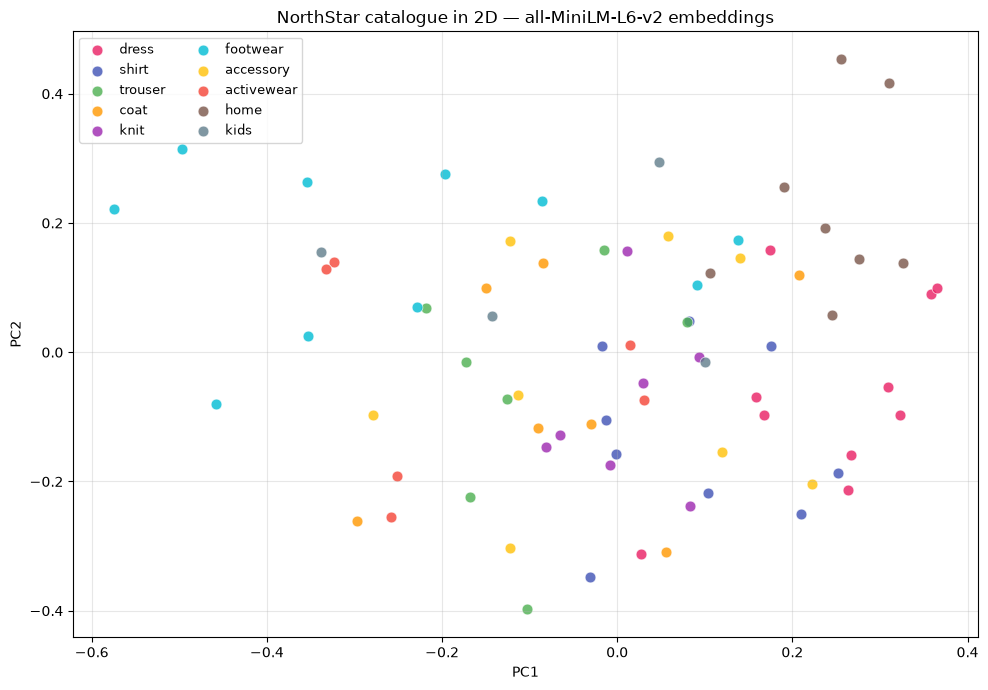

PCA captured 11.3% of variance in 2D.


In [16]:
# Project all 76 catalogue vectors from 384-D down to 2-D so we can plot them.
pca = PCA(n_components=2)
coords = pca.fit_transform(catalogue_embeddings)

CATEGORY_COLOURS = {
    'dress': '#E91E63', 'shirt': '#3F51B5', 'trouser': '#4CAF50',
    'coat': '#FF9800', 'knit': '#9C27B0', 'footwear': '#00BCD4',
    'accessory': '#FFC107', 'activewear': '#F44336',
    'home': '#795548', 'kids': '#607D8B',
}

fig, ax = plt.subplots(figsize=(10, 7))
# Colour by category — dresses, footwear and home goods form clear groups; shirts and knits overlap more
for cat, colour in CATEGORY_COLOURS.items():
    mask = df['category'] == cat
    ax.scatter(coords[mask, 0], coords[mask, 1],
               c=colour, label=cat, s=60, alpha=0.8, edgecolor='white', linewidth=0.5)
ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
ax.set_title(f"NorthStar catalogue in 2D — {MODEL_NAME} embeddings")
ax.legend(loc='best', fontsize=9, ncol=2)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
# The model was never told the categories — it deduced them purely from English.
# That clustering is the geometric meaning of an embedding.

print(f"PCA captured {pca.explained_variance_ratio_.sum():.1%} of variance in 2D.")

Look at the structure. Even compressed to 2D you can see:

- Dresses gather together on the right
- Home goods (towels, vases, cushions) sit apart from clothing, in the top-right
- Footwear mostly sits on the left / upper-left
- Shirts, coats, knits and accessories overlap more in the middle — this 2D picture keeps only ~11% of the information in the 384-D vectors (see the PCA % printed above), so some categories that are separate in 384-D get squashed together here

The model never saw the category labels. It deduced these groupings purely from English. That's the geometric meaning of a sentence embedding.

## 8 · Recap

What changed from NB 02 to NB 03:

| Aspect | Toy embedding (NB 02) | Pretrained (NB 03) |
|--------|----------------------|--------------------|
| Training corpus | 76 product descriptions | > 1 billion sentence pairs |
| Vocabulary | 552 words | 30,000 subword tokens |
| Embedding dim | 552 (raw) or 50 (SVD) | 384 |
| Context-aware | No (static) | Yes (transformer) |
| Sentence-level | No (word-only) | Yes (native) |
| frock ↔ dress cosine | 0.035 | 0.249 |
| sundress ↔ dress cosine | 0.054 | 0.509 |
| Top-1 accuracy (8-query bench) | n/a | 6/8 (75%) vs keyword 5/8 (62%) |

The model does the heavy lifting. We just call `.encode()` and store the result.

**Honest assessment:** top-1 went from 62% to around 75%, and of the two misses, Lila lands at rank 3 and Trail Windbreaker at rank 8. That's a real but modest win — most production search systems combine semantic ranking with structured filters (category, price range, colour). NB 04 builds a clean search-engine wrapper and explores TF-IDF as a complement.

**Next:** turn this into a production-grade search engine. NB 04.
> ℹ️ **About the exact numbers quoted here:** cosine values like these come from a live model, so your output may differ slightly (e.g. 0.249 vs 0.251) depending on your `sentence-transformers` / model version. Treat every quoted score as *approximately* right — the pattern is what matters, not the third decimal place.


---

## 🟡 Extension — self-study after class

*Skipping this section will not affect your understanding of later lessons. Come back to it when you have time and want to go deeper.*

## E1 · Encoding speed and batching

How fast can the model embed at scale? Try encoding 1000 sentences and see throughput. Increase batch_size and see if it helps on your machine.

In [17]:
# (Optional) How many sentences per second can the model embed, and does a bigger batch help?

# Replicate the catalogue 14× to get ~1000 documents
big_corpus = (documents * 14)[:1000]
print(f"Embedding {len(big_corpus)} sentences...")

t0 = time.time()
emb = model.encode(big_corpus, batch_size=32, show_progress_bar=False)
t_batch = time.time() - t0
print(f"  batch_size=32 : {t_batch:.2f}s  ({len(big_corpus)/t_batch:.0f} sentences/sec)")

t0 = time.time()
emb = model.encode(big_corpus, batch_size=128, show_progress_bar=False)  # bigger batch
t_batch = time.time() - t0
print(f"  batch_size=128: {t_batch:.2f}s  ({len(big_corpus)/t_batch:.0f} sentences/sec)")
print('\nLarger batches usually help on GPU; CPU gains depend on memory bandwidth.')

Embedding 1000 sentences...
  batch_size=32 : 1.06s  (939 sentences/sec)
  batch_size=128: 1.00s  (998 sentences/sec)

Larger batches usually help on GPU; CPU gains depend on memory bandwidth.


## E2 · Average word vectors as a baseline

Before sentence-transformers, the cheap way to embed a sentence was to **average its word vectors**. This loses word order but is computationally trivial. Compare it to MiniLM.

In [18]:
# (Optional) A cheap baseline: build a sentence vector by averaging its word vectors.
# Blazing fast but throws away word order, so weaker than a transformer.
import re

def tokens(text):
    return re.findall(r'\w+', text.lower())

# Build small word embedding (subset of vocab; reuse logic from NB02)
all_text = ' '.join(documents).lower()
vocab = sorted(set(re.findall(r'\w+', all_text)))
V = len(vocab)
w2i = {w: i for i, w in enumerate(vocab)}

# Cheap one-hot averaging "embedding" — basically TF averaging
def avg_word_vec(text):
    toks = [w for w in tokens(text) if w in w2i]
    if not toks: return np.zeros(V)
    v = np.zeros(V)
    for t in toks: v[w2i[t]] += 1
    return v / len(toks)  # average over the sentence's words — loses word order

# Try one query
query = "blue summer dress"
q_vec = avg_word_vec(query)
doc_vecs = np.vstack([avg_word_vec(d) for d in documents])
from sklearn.metrics.pairwise import cosine_similarity as cs
sims = cs(q_vec.reshape(1, -1), doc_vecs)[0]
top_idx = np.argsort(-sims)[:5]
print('Averaged one-hot vectors — top 5 for blue summer dress:')
for i in top_idx:
    name = df.iloc[i]['name']
    print(f"  {name:40s} score={sims[i]:.3f}")

Averaged one-hot vectors — top 5 for blue summer dress:
  Marina Wrap Dress                        score=0.258
  Holly Knit Jumper Dress                  score=0.258
  Frost Linen Shirt                        score=0.154
  Sand Espadrille Sandals                  score=0.154
  Sienna Bodycon Dress                     score=0.149


Word-vector averaging is a real technique. It's worse than transformer-based encoders because it discards word order and uses uniform weights — but it's blazing fast and works as a baseline. For tiny corpora and latency-critical applications, this is still used. For real search, use the pretrained model.